In [295]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [296]:
import pandas as pd

In [297]:
df = pd.read_csv("/content/drive/MyDrive/customer churn/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [298]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [299]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


**Exploratory Data Analysis**

In [300]:
import matplotlib.pyplot as plt
import seaborn as sns

<Axes: xlabel='Churn', ylabel='count'>

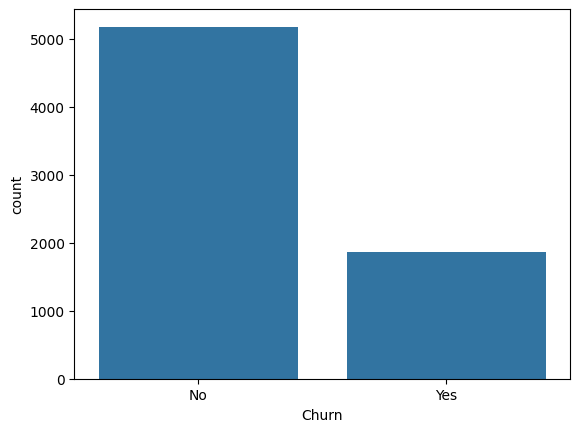

In [301]:
sns.countplot(x="Churn",data=df)

Churn is near 5000 not churn near 2000 so the data is inbalanced

<Axes: xlabel='Contract', ylabel='count'>

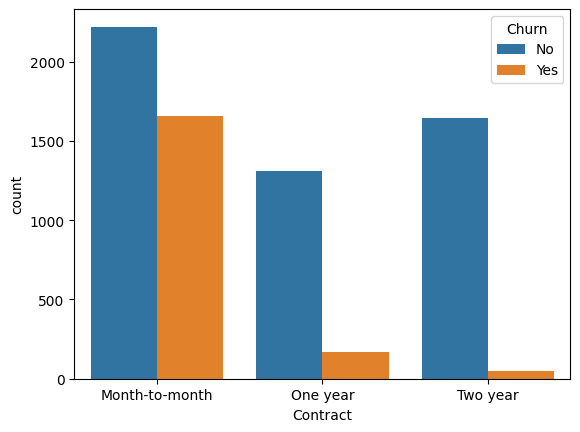

In [302]:
sns.countplot(x='Contract',hue="Churn",data=df)

In [303]:
for i in df.Contract.unique():
  print("Contract:",i,"percentage of non churn per churn",df[(df.Contract=="Month-to-month") & (df.Churn=="No")].shape[0]/df[(df.Contract==i) & (df.Churn=="Yes")].shape[0])

Contract: Month-to-month percentage of non churn per churn 1.3413897280966767
Contract: One year percentage of non churn per churn 13.373493975903614
Contract: Two year percentage of non churn per churn 46.25


month to month has the biggest number of not churn and churn near 1700 churn which is huge compared to the other two types for one year its less than 200 and two year its less than 100 even tho the number of not churn is big also on month to month but the ratio of not churn and churn is very small on month to month we calculated using  

so month to month clienst are most likely to churn beacuase the contarct is too short but for 1 year or two year the probaility of churn is very small so the company need to convince more people to go for one or two year contract by offering convincing exciting offers like reducing money or higehr qulity or extra offers

<Axes: xlabel='tenure', ylabel='Count'>

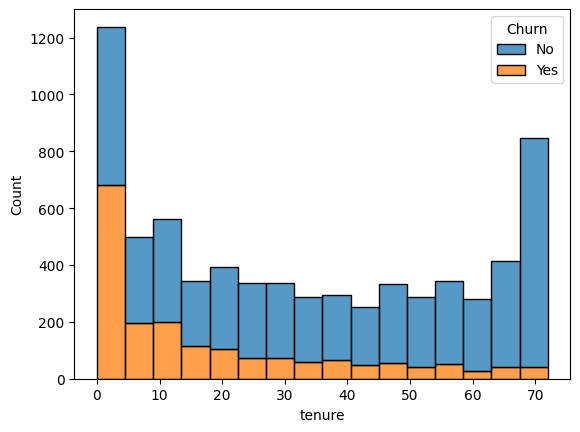

In [304]:
sns.histplot(data=df,x="tenure",hue='Churn', multiple='stack')

the count of tenure overall is going down till 70 months and it s raises very fast which means that we have a lot of old loyal client second is that we also have a lot of new clients as 1200 client are less than 5 months of using our company third the number of churn goes down dramatically after the 5 months from 700 churn client to 200 client for 10 months tenure so as suggestion the company needs t target new clients less tan 5 months tenure and offer exculsive offers trying to keep them to the company for more time before they churn

In [305]:
df=df.drop("customerID",axis=1)

In [306]:
gender={"Male":1,"Female":0}

In [307]:
df.gender=df.gender.map(gender)

In [308]:
df["gender"][5030]

np.int64(1)

In [309]:
o=df.dtypes[df.dtypes=="object"]
yes={"Yes","No","No phone service","No internet service"}
L=[]
for i in o.index:
  if set(df[i].unique()).issubset(yes):
    L.append(i)

In [310]:
L

['Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'PaperlessBilling',
 'Churn']

In [311]:
encode={"Yes":1,"No":0,"No phone service":0,"No internet service":0}
for i in L:
  df[i]=df[i].map(encode)

In [312]:
df.TotalCharges=pd.to_numeric(df.TotalCharges,errors="coerce")

In [313]:
lasto=df.dtypes[df.dtypes=="object"]

In [314]:
lasto

,0
InternetService,object
Contract,object
PaymentMethod,object


In [315]:
for i in lasto.index:
  print(df[i].unique())

['DSL' 'Fiber optic' 'No']
['Month-to-month' 'One year' 'Two year']
['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']


In [316]:
df.InternetService[df['InternetService']=="No"].count()

np.int64(1526)

In [317]:
for i in lasto.index:
  df=pd.concat([df,pd.get_dummies(df[i])],axis=1)

In [318]:
df

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,DSL,Fiber optic,No,Month-to-month,One year,Two year,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
0,0,0,1,0,1,0,0,DSL,0,1,...,True,False,False,True,False,False,False,False,True,False
1,1,0,0,0,34,1,0,DSL,1,0,...,True,False,False,False,True,False,False,False,False,True
2,1,0,0,0,2,1,0,DSL,1,1,...,True,False,False,True,False,False,False,False,False,True
3,1,0,0,0,45,0,0,DSL,1,0,...,True,False,False,False,True,False,True,False,False,False
4,0,0,0,0,2,1,0,Fiber optic,0,0,...,False,True,False,True,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,0,1,1,24,1,1,DSL,1,0,...,True,False,False,False,True,False,False,False,False,True
7039,0,0,1,1,72,1,1,Fiber optic,0,1,...,False,True,False,False,True,False,False,True,False,False
7040,0,0,1,1,11,0,0,DSL,1,0,...,True,False,False,True,False,False,False,False,True,False
7041,1,1,1,0,4,1,1,Fiber optic,0,0,...,False,True,False,True,False,False,False,False,False,True


In [319]:
df=df.rename(columns={"No":"No internet service"})

In [320]:
df

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,DSL,Fiber optic,No internet service,Month-to-month,One year,Two year,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
0,0,0,1,0,1,0,0,DSL,0,1,...,True,False,False,True,False,False,False,False,True,False
1,1,0,0,0,34,1,0,DSL,1,0,...,True,False,False,False,True,False,False,False,False,True
2,1,0,0,0,2,1,0,DSL,1,1,...,True,False,False,True,False,False,False,False,False,True
3,1,0,0,0,45,0,0,DSL,1,0,...,True,False,False,False,True,False,True,False,False,False
4,0,0,0,0,2,1,0,Fiber optic,0,0,...,False,True,False,True,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,0,1,1,24,1,1,DSL,1,0,...,True,False,False,False,True,False,False,False,False,True
7039,0,0,1,1,72,1,1,Fiber optic,0,1,...,False,True,False,False,True,False,False,True,False,False
7040,0,0,1,1,11,0,0,DSL,1,0,...,True,False,False,True,False,False,False,False,True,False
7041,1,1,1,0,4,1,1,Fiber optic,0,0,...,False,True,False,True,False,False,False,False,False,True


In [321]:
for i in lasto.index:
  df=df.drop(i,axis=1)

In [322]:
df.dtypes[df.dtypes=="object"]

,0


In [323]:
df.isnull().sum()[df.isnull().sum()!=0]

,0
TotalCharges,11


In [324]:
df.TotalCharges[df.TotalCharges.isnull()]=df.TotalCharges.mean()

/tmp/ipykernel_5075/4224033408.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df.TotalCharges[df.TotalCharges.isnull()]=df.TotalCharges.mean()
/tmp/ipykernel_5075/4224033408.py:1: SettingWithCopyWarning: 
A value is trying to be set on 

In [325]:
df.isnull().sum()[df.isnull().sum()!=0]

,0


In [326]:
corr_matrix=df.corr(numeric_only=True)

<Axes: >

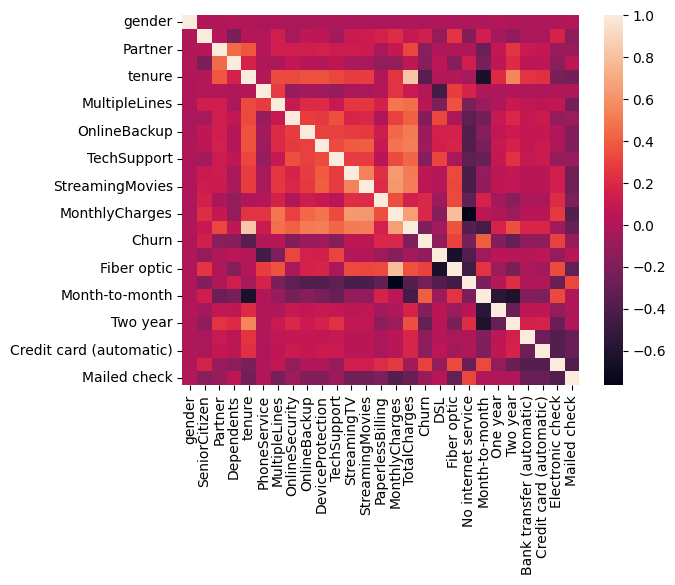

In [327]:
sns.heatmap(corr_matrix)

there is a strong positive correlation betweenn tenure and total chargeswhcih is normal because the more tenure the more the the charges uteh client spend and monthly charges and fiber optic which means that fiber optic is exepnsive  also there is a strong negative corrlation between month to month and tenure because the more tenure the more the client goes for 1 or 2 year contract also we have monthly charges and no internet services whcih means the having internet service is exepnsive *

In [328]:
df.shape

(7043, 27)

In [329]:
df.Churn.shape

(7043,)

In [330]:
y=df.Churn

In [331]:
X=df.drop("Churn",axis=1)

In [332]:
X.shape

(7043, 26)

In [333]:
y.shape

(7043,)

In [334]:
from sklearn.model_selection import train_test_split

In [335]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [336]:
from sklearn.linear_model import LogisticRegression

In [337]:
model = LogisticRegression()
model.fit(X_train,y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [338]:
y_pred=model.predict(X_test)

In [339]:
y_pred

array([1, 0, 0, ..., 0, 0, 0])

In [340]:
from sklearn.metrics import accuracy_score

In [341]:
accuracy=accuracy_score(y_test,y_pred)
print("accuracy:",accuracy)

accuracy: 0.8218594748048261


In [342]:
y.value_counts()[1]/y.shape

array([0.26536987])

In [343]:
y.value_counts()[0]/y.shape

array([0.73463013])

In [344]:
y.value_counts()

,count
Churn,
0,5174
1,1869


In [345]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.86      0.91      0.88      1036
           1       0.69      0.59      0.64       373

    accuracy                           0.82      1409
   macro avg       0.78      0.75      0.76      1409
weighted avg       0.82      0.82      0.82      1409



In [346]:
from sklearn.linear_model import LogisticRegression

In [347]:
newmodel=LogisticRegression(class_weight="balanced")

In [348]:
newmodel.fit(X_train,y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(class_weight='balanced')

In [349]:
newy=newmodel.predict(X_test)

In [350]:
print(classification_report(y_test,newy))

              precision    recall  f1-score   support

           0       0.93      0.72      0.81      1036
           1       0.52      0.84      0.64       373

    accuracy                           0.75      1409
   macro avg       0.72      0.78      0.72      1409
weighted avg       0.82      0.75      0.76      1409



In [351]:
from sklearn.ensemble import RandomForestClassifier

In [352]:
rfmodel=RandomForestClassifier()

In [353]:
rfmodel.fit(X_train,y_train)

RandomForestClassifier()

In [354]:
rfy=rfmodel.predict(X_test)

In [355]:
print(classification_report(y_test,rfy))

              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1036
           1       0.63      0.48      0.54       373

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.70      1409
weighted avg       0.78      0.79      0.78      1409



In [ ]:
!pip install xgboost

In [ ]:
from xgboost import XGBClassifier

In [ ]:
rfbmodel=RandomForestClassifier(class_weight="balanced")

In [ ]:
rfbmodel.fit(X_train,y_train)

In [ ]:
rfbpredict=rfbmodel.predict(X_test)

In [ ]:
print(classification_report(y_test,rfbpredict))

In [ ]:
xgmodel=XGBClassifier(scale_pos_weight=2.7683253076511503)

In [ ]:
y[y==0].count()/y[y==1].count()

In [ ]:
xgmodel.fit(X_train,y_train)

In [ ]:
xgy=xgmodel.predict(X_test)

In [ ]:
print(classification_report(y_test,xgy))

In [ ]:
import joblib

In [ ]:
joblib.dump(newmodel,"churn_model.pkl")

In [ ]:
loaded_model=joblib.load("churn_model.pkl")
print(classification_report(y_test,loaded_model.predict(X_test)))

In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

In [ ]:
DT=DecisionTreeClassifier()

In [ ]:
GB=GradientBoostingClassifier()

In [ ]:
DT.fit(X_train,y_train)

In [ ]:
GB.fit(X_train,y_train)

In [ ]:
DTp=DT.predict(X_test)
GBP=GB.predict(X_test)

In [ ]:
print(classification_report(y_test,DTp))

In [ ]:
print(classification_report(y_test,GBP))

| Model | Recall (Churners) |
|-------|------------------|
| Logistic Regression (balanced) | 0.84 |
| Random Forest (balanced) | 0.45 |
| XGBoost | 0.68 |
| Decision Tree | 0.50 |
| Gradient Boosting | 0.54 |

as the data is imblanced the recall is criteria we will use to choose the best model and in this case its LR balanced with 0.84 recall